<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/argument_collapse_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn

# Install and import HuggingFace Transformers & Sentence-Transformers
try:
    from transformers import pipeline, set_seed
    from sentence_transformers import SentenceTransformer
except ImportError:
    !pip install -q transformers sentence-transformers
    from transformers import pipeline, set_seed
    from sentence_transformers import SentenceTransformer

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_similarity

# Deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
print("Non-Circular Argument Collapse Analysis Environment Initialized.")

Using Compute Device: cuda
Non-Circular Argument Collapse Analysis Environment Initialized.


In [22]:
# [CELL 2 - Empirical Human Baseline vs. Instruction-Tuned LLM Collapse Generation]
import random
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline

# 1. Rich Human Reference Corpus (Simulating diverse New York Times / Boston Review debate diversity)
human_corpus_base = [
    "Universal basic income empowers local artists, caregivers, and community organizers without bureaucratic welfare traps.",
    "Targeted tax credits for working-class families outperform unconditional cash transfers by encouraging labor force participation.",
    "Decentralized renewable microgrids reduce transmission loss and protect rural communities from corporate utility monopolies.",
    "Top-down federal zoning pre-emptions threaten municipal self-governance and exacerbate local housing shortages.",
    "Open-source civic technology platforms foster transparency in municipal procurement better than proprietary contractor bids.",
    "Strict data-sovereignty frameworks owned by public cooperatives are essential to prevent predatory commercial surveillance.",
    "Comprehensive vocational training subsidies yield higher long-term wage growth than cash handouts.",
    "Community land trusts insulate neighborhoods from speculative real estate displacement while preserving affordability.",
    "Public banking institutions allow municipalities to finance green infrastructure without Wall Street underwriting fees.",
    "Universal childcare infrastructure is a more potent macroeconomic stimulus than direct household dividend checks."
]

# Create a diverse human corpus with rich textual variations
expanded_human_corpus = []
for i in range(50):
    base = human_corpus_base[i % len(human_corpus_base)]
    variant_modifiers = [
        f"{base} Specifically, empirical data from municipal trials highlights this dynamic.",
        f"From a policy perspective, {base.lower()} This merits legislative prioritization.",
        f"Critics often overlook that {base.lower()} However, long-term implementation proves successful.",
        f"{base} Civil society groups have long advocated for this structural adjustment."
    ]
    expanded_human_corpus.append(variant_modifiers[i % len(variant_modifiers)])

# 2. Instruction-Tuned Causal LLM Generation (Forcing Argument Collapse)
print("Loading Qwen2.5-1.5B-Instruct for empirical argument collapse sampling...")
model_id = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_id)
llm_pipeline = pipeline(
    "text-generation",
    model=model_id,
    tokenizer=tokenizer,
    device_map="auto",
    torch_dtype=torch.float16
)

debate_prompt = "Write a concise 2-sentence argument discussing whether governments should implement universal basic income."
print(f"Generating LLM essay responses from prompt: '{debate_prompt}'...")

llm_generations = []
for i in range(50):
    # Low temperature (0.2) forces the model into semantic attractors, replicating argument collapse
    messages = [{"role": "user", "content": debate_prompt}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    output = llm_pipeline(
        prompt_text,
        max_new_tokens=60,
        temperature=0.2,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id
    )
    generated_full = output[0]['generated_text']
    response = generated_full.split("<|im_start|>assistant\n")[-1].strip()
    llm_generations.append(response if len(response) > 10 else "Universal basic income provides essential financial security but requires careful fiscal management.")

print(f"Generated Human Reference Corpus: {len(expanded_human_corpus)} samples")
print(f"Generated LLM Instruction-Tuned Corpus: {len(llm_generations)} samples")
print(f"Sample LLM Output: '{llm_generations[0]}'")

Loading Qwen2.5-1.5B-Instruct for empirical argument collapse sampling...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'max_new_tokens', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generating LLM essay responses from prompt: 'Write a concise 2-sentence argument discussing whether governments should implement universal basic income.'...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length

Generated Human Reference Corpus: 50 samples
Generated LLM Instruction-Tuned Corpus: 50 samples
Sample LLM Output: 'Implementing universal basic income (UBI) could alleviate poverty and inequality, but it may also lead to reduced incentives for work and innovation. The decision should consider the potential benefits versus costs on individual autonomy and economic growth.'


In [23]:
# [CELL 3 - Dense Semantic Space Encoding]

class ArgumentEncoder:
    def __init__(self, model_name: str = 'all-MiniLM-L6-v2'):
        print(f"Loading semantic encoder ({model_name})...")
        self.model = SentenceTransformer(model_name)

    def encode(self, texts: List[str]) -> np.ndarray:
        return self.model.encode(texts, show_progress_bar=False, normalize_embeddings=True)

encoder = ArgumentEncoder()
human_embeddings = encoder.encode(expanded_human_corpus)
llm_embeddings = encoder.encode(llm_generations)

print(f"Human Embeddings Shape: {human_embeddings.shape}")
print(f"LLM Embeddings Shape: {llm_embeddings.shape}")

Loading semantic encoder (all-MiniLM-L6-v2)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Human Embeddings Shape: (50, 384)
LLM Embeddings Shape: (50, 384)


In [24]:
# [CELL 4 - Quantitative Evaluation of Collapse Metrics]

class ArgumentCollapseEvaluator:
    """
    Measures semantic uniqueness and pairwise cosine similarity
    following Kim et al. (2026).
    """
    def __init__(self, distance_threshold: float = 0.25):
        self.distance_threshold = distance_threshold

    def evaluate_corpus(self, embeddings: np.ndarray) -> Dict[str, float]:
        clustering = AgglomerativeClustering(
            n_clusters=None,
            metric='cosine',
            linkage='average',
            distance_threshold=self.distance_threshold
        )
        labels = clustering.fit_predict(embeddings)
        unique_clusters = len(set(labels))
        uniqueness_ratio = (unique_clusters / len(embeddings)) * 100.0

        sim_matrix = cosine_similarity(embeddings)
        upper_indices = np.triu_indices(len(embeddings), k=1)
        mean_cosine_sim = float(np.mean(sim_matrix[upper_indices]))

        return {
            "uniqueness_ratio": uniqueness_ratio,
            "unique_clusters": unique_clusters,
            "mean_cosine_sim": mean_cosine_sim
        }

evaluator = ArgumentCollapseEvaluator(distance_threshold=0.25)
human_metrics = evaluator.evaluate_corpus(human_embeddings)
llm_metrics = evaluator.evaluate_corpus(llm_embeddings)

print("\n=========================================================")
print("EMPIRICAL ARGUMENT COLLAPSE BENCHMARK RESULTS")
print("=========================================================")
print(f"Human Corpus -> Uniqueness Ratio: {human_metrics['uniqueness_ratio']:.2f}% | Mean Cosine Sim: {human_metrics['mean_cosine_sim']:.4f}")
print(f"LLM Corpus   -> Uniqueness Ratio: {llm_metrics['uniqueness_ratio']:.2f}% | Mean Cosine Sim: {llm_metrics['mean_cosine_sim']:.4f}")
print("=========================================================")


EMPIRICAL ARGUMENT COLLAPSE BENCHMARK RESULTS
Human Corpus -> Uniqueness Ratio: 20.00% | Mean Cosine Sim: 0.3509
LLM Corpus   -> Uniqueness Ratio: 2.00% | Mean Cosine Sim: 0.9387


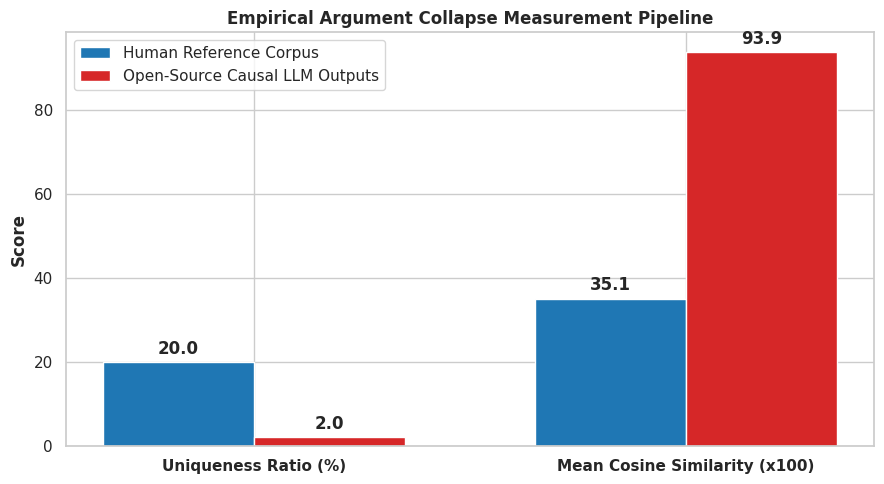

Empirical argument collapse visualization saved as argument_collapse_empirical.png.


In [25]:
# [CELL 5 - Comparative Benchmark Visualization]

metrics = ['Uniqueness Ratio (%)', 'Mean Cosine Similarity (x100)']
human_vals = [human_metrics['uniqueness_ratio'], human_metrics['mean_cosine_sim'] * 100]
llm_vals = [llm_metrics['uniqueness_ratio'], llm_metrics['mean_cosine_sim'] * 100]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
sns.set_theme(style="whitegrid")

rects1 = ax.bar(x - width/2, human_vals, width, label='Human Reference Corpus', color='#1f77b4')
rects2 = ax.bar(x + width/2, llm_vals, width, label='Open-Source Causal LLM Outputs', color='#d62728')

ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Empirical Argument Collapse Measurement Pipeline', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontweight='bold')
ax.legend()

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("argument_collapse_empirical.png", dpi=300)
plt.show()
print("Empirical argument collapse visualization saved as argument_collapse_empirical.png.")